In [ ]:
!pip install tensorflow

In [ ]:
from datasets import load_dataset
import numpy as np
import tensorflow as tf

In [ ]:
data=load_dataset("nu-delta/utkface",split='train')

README.md:   0%|          | 0.00/467 [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  343MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  343MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  362MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/23705 [00:00<?, ? examples/s]

In [ ]:
data.shuffle(seed=42)

Dataset({
    features: ['image', 'file_name', 'age', 'gender', 'ethnicity', 'date'],
    num_rows: 23705
})

In [ ]:
split=data.train_test_split(test_size=0.2,seed=42)

In [ ]:
train=split['train']
test=split['test']

In [ ]:
output_signature=(
    tf.TensorSpec(shape=(224,224,3),dtype=np.float32),
    {
    'age':tf.TensorSpec(shape=(),dtype=np.int64),
    'gender':tf.TensorSpec(shape=(),dtype=np.int64)}
)

In [ ]:
BATCH_SIZE=32
IMAGE_SIZE=(224,224)

In [ ]:
train[0]

{'image': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=200x200>,
 'file_name': '16_0_0_20170110231810810.jpg',
 'age': 16,
 'gender': 'Male',
 'ethnicity': 'White',
 'date': '20170110231810810'}

In [ ]:
def my_generator(dataset):
  def generator():
    for data in dataset:
      image=data['image'].convert("RGB")
      image_tensor=tf.convert_to_tensor(image,dtype=tf.float32)
      image_resized=tf.image.resize(image_tensor,IMAGE_SIZE)/255.0

      if data['gender'].lower()=='male':
        label= 1
      else:
        label= 0

      yield image_resized,{'gender':tf.cast(label,np.int64),'age':tf.cast(data['age'],np.int64)}
  return generator;

In [ ]:
train_dataset=tf.data.Dataset.from_generator(
    my_generator(train),
    output_signature=output_signature
).repeat().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset=tf.data.Dataset.from_generator(
    my_generator(test),
    output_signature=output_signature
).repeat().batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout,Input,RandomFlip,RandomZoom,RandomRotation,Dense,GlobalAveragePooling2D

In [ ]:
input=Input(shape=(224,224,3))

# Sequential Data Augmentation

In [ ]:
data_augmentation=Sequential()
data_augmentation.add(RandomFlip("horizontal"))
data_augmentation.add(RandomRotation(0.2))
data_augmentation.add(RandomZoom(0.1))

In [ ]:
inp=data_augmentation(input)

# Convolution Layers

In [ ]:
conv1=Conv2D(32,kernel_size=(3,3),padding="valid",activation="relu")(inp)
batch1=BatchNormalization()(conv1)
max1=MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')(batch1)

conv2=Conv2D(64,kernel_size=(3,3),padding="valid",activation="relu")(max1)
batch2=BatchNormalization()(conv2)
max2=MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')(batch2)

conv3=Conv2D(128,kernel_size=(3,3),padding="valid",activation="relu")(max2)
batch3=BatchNormalization()(conv3)
max3=MaxPooling2D(pool_size=(2,2),strides=2,padding='valid')(batch3)

# flatten=Flatten()(max3)
averagePooling=GlobalAveragePooling2D()(max3)

# Dense layer for Classification (Gender)

In [ ]:
dense1=Dense(64,activation='relu')(averagePooling)
drop1=Dropout(0.3)(dense1)

dense2=Dense(32,activation='relu')(drop1)
drop2=Dropout(0.3)(dense2)

dense3=Dense(1,activation='sigmoid',name='gender')(drop2)

# Dense layer for Regression (Age)

In [ ]:
dense4=Dense(64,activation='relu')(averagePooling)
drop4=Dropout(0.3)(dense4)

dense5=Dense(32,activation='relu')(drop4)
drop5=Dropout(0.3)(dense5)

dense6=Dense(1,activation='linear',name='age')(drop5)

In [ ]:
from keras.models import Model

In [ ]:
model=Model(inputs=input,outputs=[dense3,dense6])

In [ ]:
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 222, 222,  │        896 │ sequential_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 222, 222,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 111, 111,  │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 109, 109,  │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 109, 109,  │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 54, 54,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 52, 52,    │     73,856 │ max_pooling2d_4[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 52, 52,    │        512 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 26, 26,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ max_pooling2d_5[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │      2,080 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 32)        │      2,080 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 32)        │          0 │ dense_5[0][0]   

 Total params: 114,882 (448.76 KB)

 Trainable params: 114,434 (447.01 KB)

 Non-trainable params: 448 (1.75 KB)

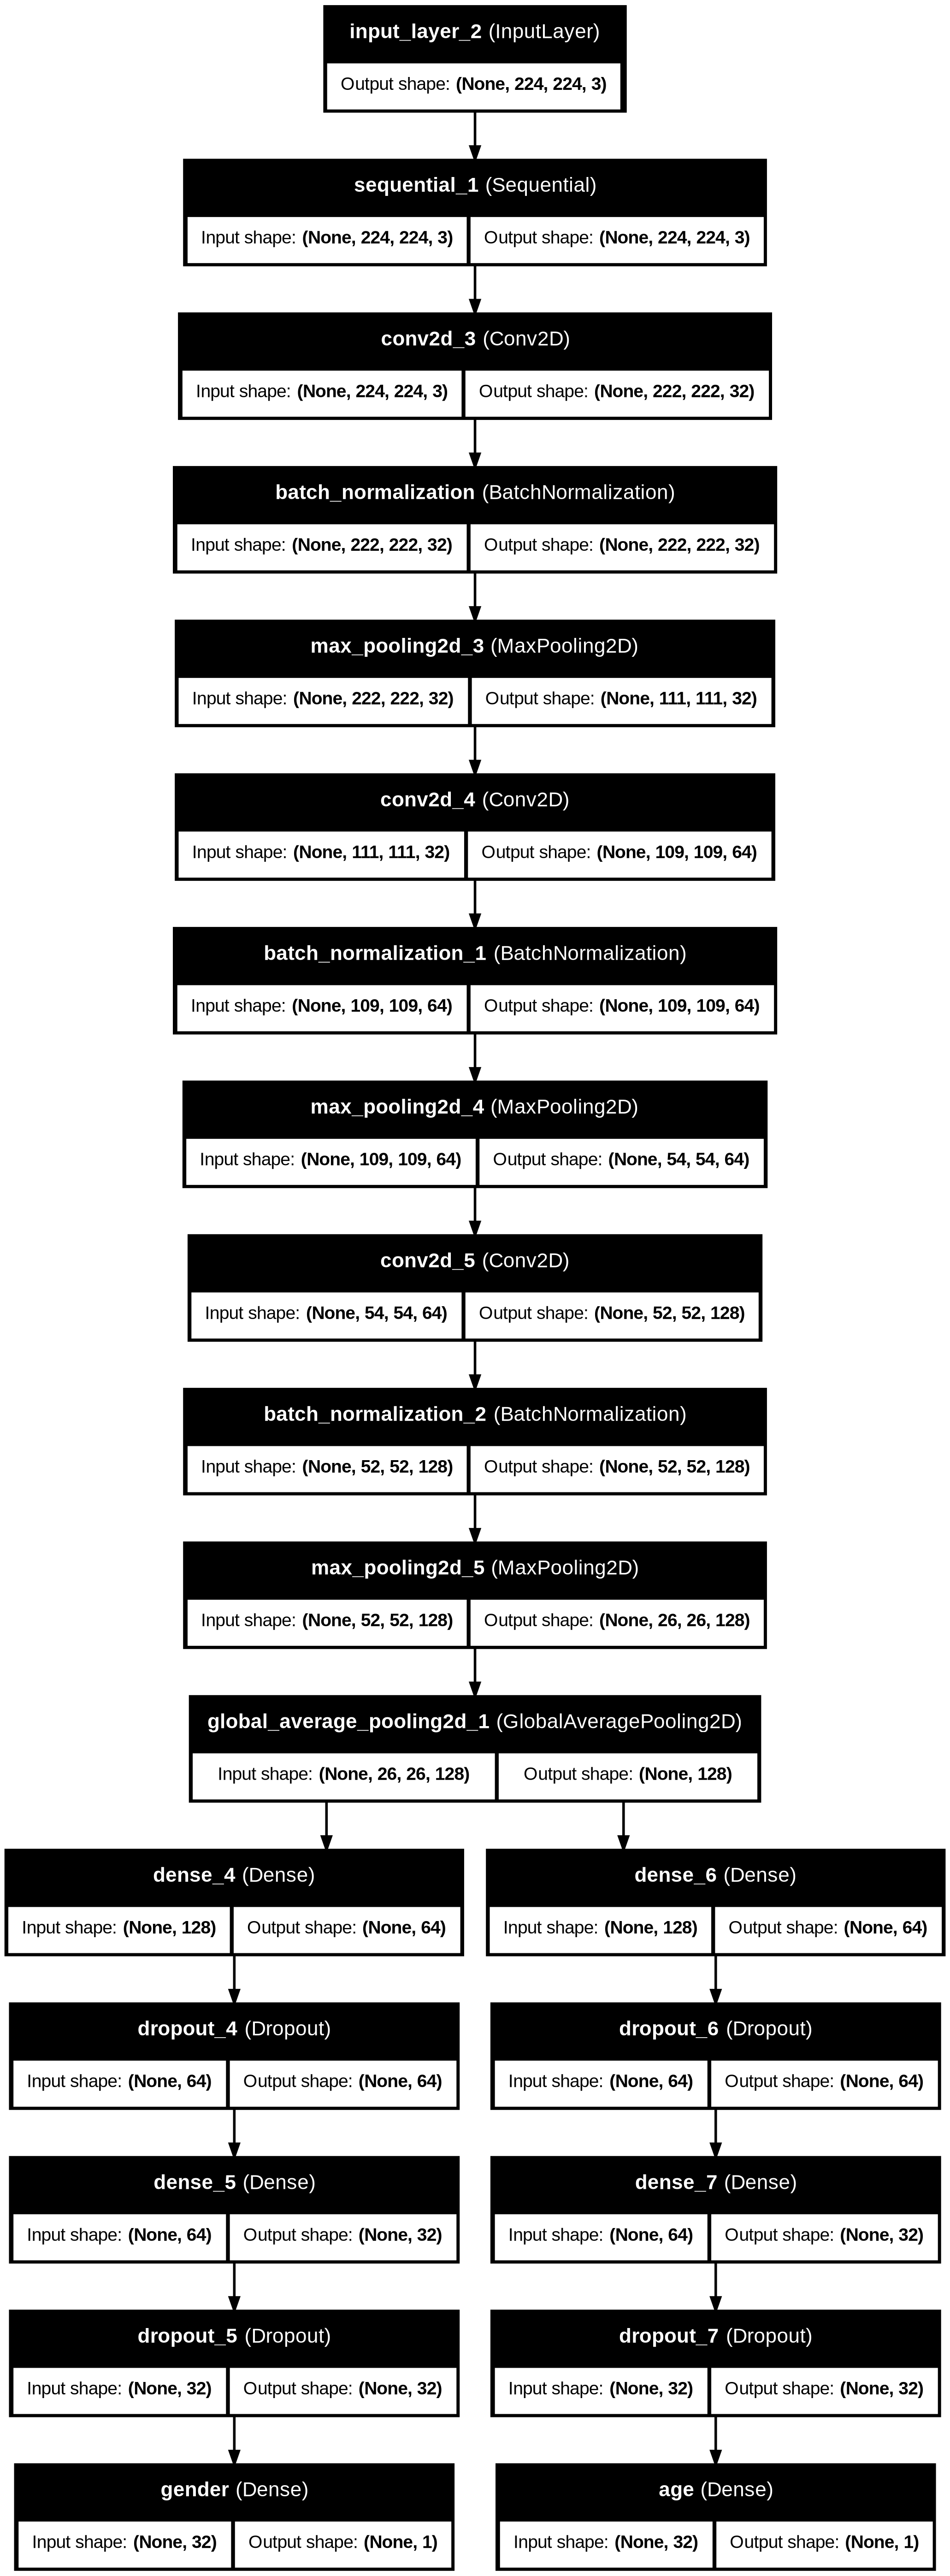

In [ ]:
from keras.utils import plot_model
plot_model(
    model,
    to_file='model_architecture.png',
    show_shapes=True,
    show_layer_names=True,
    rankdir='TB'
)

In [ ]:
model.compile(optimizer='adam',loss={'age':'mae','gender':'binary_crossentropy'},metrics={'age':'mae','gender':'accuracy'},loss_weights={'age':1,'gender':99})

In [ ]:
from keras.callbacks import EarlyStopping,ReduceLROnPlateau

In [ ]:
# callback=EarlyStopping(monitor='val_gender_accuracy',patience=3,restore_best_weights=True)
ReduceLR=ReduceLROnPlateau(monitor='val_loss',patience=2,verbose=1,factor=0.5,min_lr=1e-6)

In [ ]:
steps_per_epoch=len(train)//BATCH_SIZE
validation_steps=len(test)//BATCH_SIZE

In [ ]:
model.fit(train_dataset,epochs=20,validation_data=test_dataset,callbacks=[ReduceLR],steps_per_epoch=steps_per_epoch,validation_steps=validation_steps)

Epoch 1/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 187s 309ms/step - age_loss: 16.9828 - age_mae: 16.9828 - gender_accuracy: 0.6109 - gender_loss: 0.6634 - loss: 82.6574 - val_age_loss: 19.8688 - val_age_mae: 19.8688 - val_gender_accuracy: 0.6195 - val_gender_loss: 0.6602 - val_loss: 85.2295 - learning_rate: 0.0010
Epoch 2/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 187s 316ms/step - age_loss: 14.6923 - age_mae: 14.6923 - gender_accuracy: 0.6431 - gender_loss: 0.6356 - loss: 77.6214 - val_age_loss: 14.4163 - val_age_mae: 14.4163 - val_gender_accuracy: 0.6429 - val_gender_loss: 0.6428 - val_loss: 78.0529 - learning_rate: 0.0010
Epoch 3/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 186s 315ms/step - age_loss: 14.2061 - age_mae: 14.2061 - gender_accuracy: 0.6618 - gender_loss: 0.6177 - loss: 75.3562 - val_age_loss: 24.2079 - val_age_mae: 24.2079 - val_gender_accuracy: 0.5405 - val_gender_loss: 0.6901 - val_loss: 92.5237 - learning_rate: 0.0010
Epoch 4/20
592/592 ━━━━━━━━━━━━━━━━━━━━ 181s 306ms/step - age_loss: 13.6812 - age_

In [ ]:
model.save("utkface_age_and_gender.keras")

In [ ]:
from PIL import Image

In [ ]:
img=Image.open('/content/boy.jpg').convert("RGB").resize((224,224))
img_arr=np.array(img,dtype=np.float32)/255.0
img_batch=np.expand_dims(img_arr,axis=0)

In [ ]:
preds=model.predict(img_batch)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


In [ ]:
labels=['female','male']
label=None
if preds[0][0][0]>0.5:
  label=labels[1]
else:
  label=labels[0]

In [ ]:
age=preds[1][0][0]

In [ ]:
preds

[array([[0.47081938]], dtype=float32), array([[18.46831]], dtype=float32)]

In [ ]:
print(f"The person is {label} of age {age:.1f}")